# 4. Analyse bivariée

Relations entre deux variables : corrélation et régression linéaire (acidité fixe / densité), tableau de contingence (qualité / alcool) et boîtes à moustaches par niveau de qualité.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("../data/processed/winequality_cleaned.csv")

In [3]:
# --- Covariance et Corrélation de Pearson ---
# La relation entre 'fixed acidity' (X) et 'density' (Y)
x = data['fixed acidity']
y = data['density']
coef_pearson = st.pearsonr(x, y)[0]
covariance_empirique = np.cov(x, y, ddof=0)[1, 0]
# Affichage
print(f"Analyse entre l'Acidité Fixe et la Densité :")
print(f"Coefficient de corrélation de Pearson : {coef_pearson:.4f}")
print(f"Covariance empirique : {covariance_empirique:.6f}")

Analyse entre l'Acidité Fixe et la Densité :
Coefficient de corrélation de Pearson : 0.6702
Covariance empirique : 0.002174



Équation de la droite : y = 0.00072x + 0.99072
Qualité du modèle (R²) : 0.4492


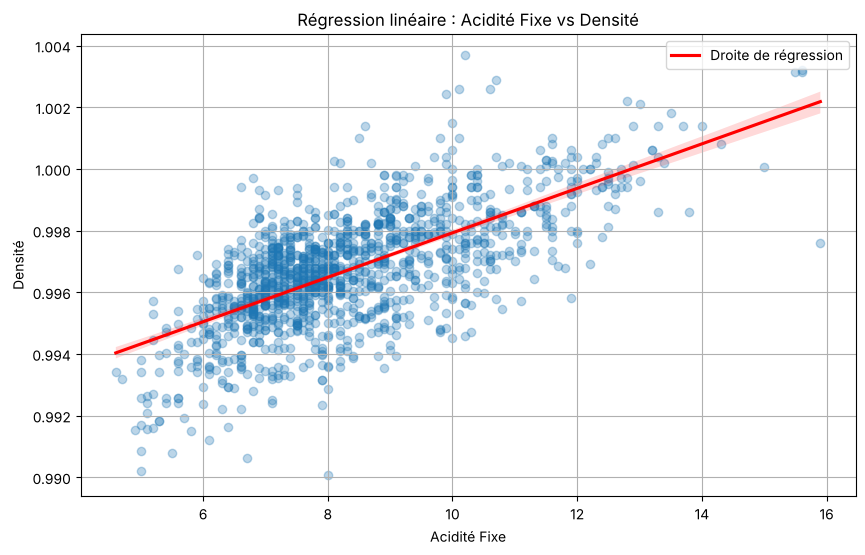

In [4]:
# --- Droite de Régression et Qualité du Modèle ---
# Les paramètres de la droite y = ax + b
slope, intercept, r_value, p_value, std_err = st.linregress(x, y)
r_squared = r_value**2
print(f"\nÉquation de la droite : y = {slope:.5f}x + {intercept:.5f}")
print(f"Qualité du modèle (R²) : {r_squared:.4f}")
# Visualisation avec droite de régression
plt.figure(figsize=(10, 6))
sns.regplot(x='fixed acidity', y='density', data=data,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red', 'label':'Droite de régression'})
plt.title('Régression linéaire : Acidité Fixe vs Densité')
plt.xlabel('Acidité Fixe')
plt.ylabel('Densité')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# --- Tableau de Contingence ---
# On discrétise l'alcool en deux catégories (Faible/Élevé) pour le croiser avec la Qualité.
data['alcohol_cat'] = pd.qcut(data['alcohol'], q=2, labels=['Alcool Faible', 'Alcool Élevé'])
tableau_contingence = pd.crosstab(data['quality'], data['alcohol_cat'])
print("\nTableau de contingence (Qualité vs Niveau d'Alcool) :")
print(tableau_contingence)


Tableau de contingence (Qualité vs Niveau d'Alcool) :
alcohol_cat  Alcool Faible  Alcool Élevé
quality                                 
3                        7             3
4                       29            24
5                      443           134
6                      216           319
7                       21           146
8                        2            15


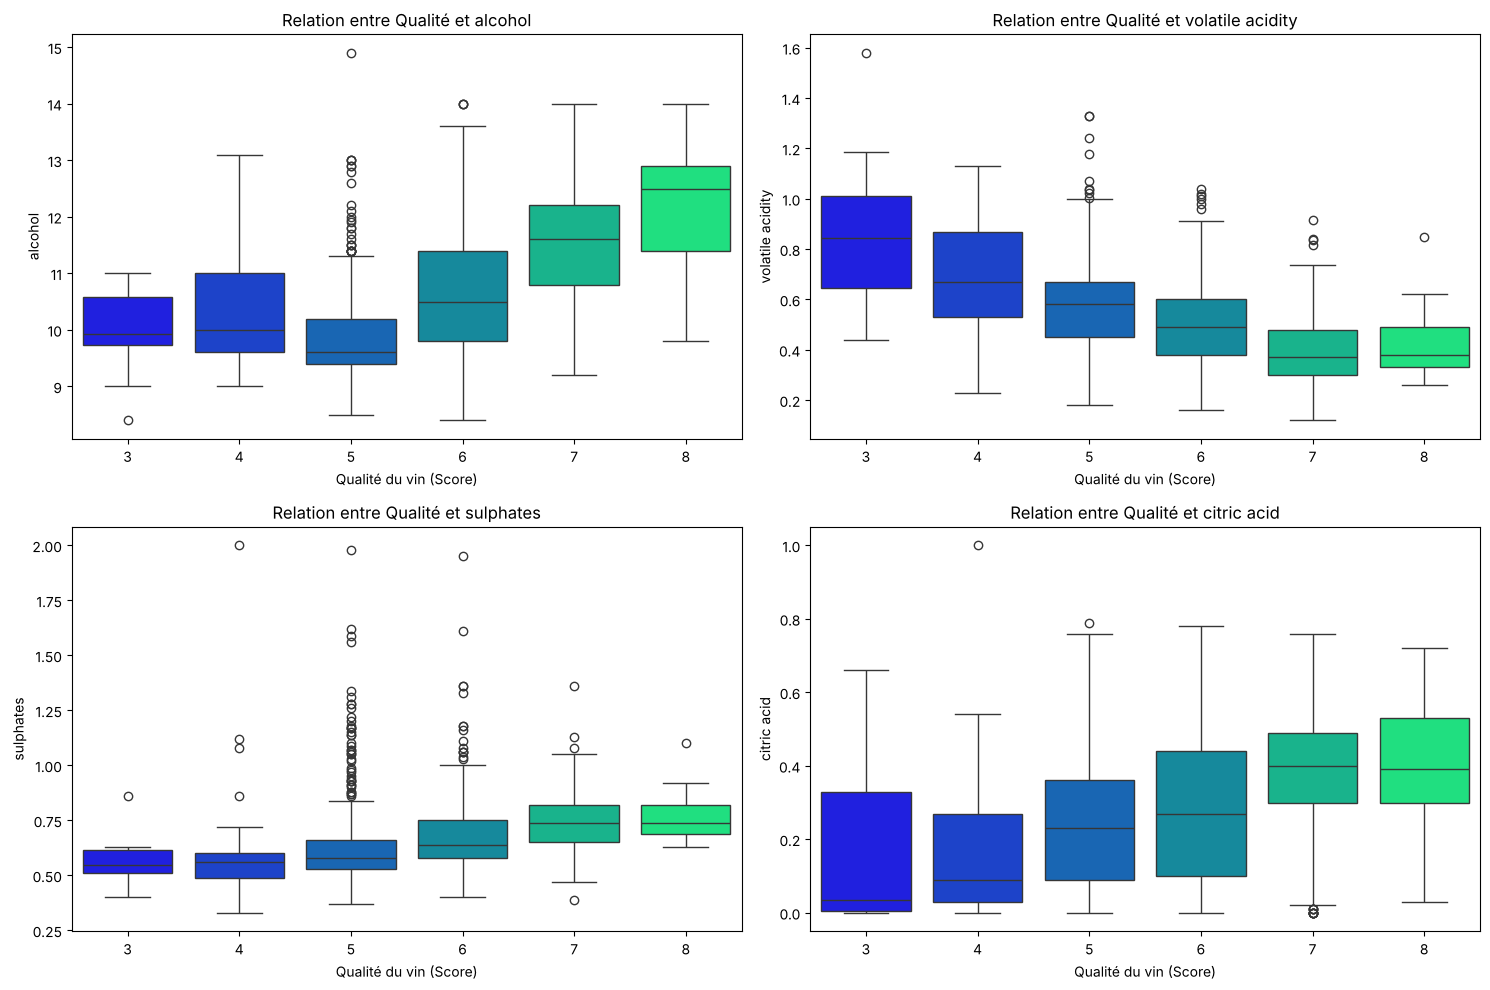

In [6]:
#---- Boite à moustache ----
# Liste des variables pour l'analyse bivariée avec la qualité
variables_a_etudier = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']

# Création des graphiques
plt.figure(figsize=(15, 10))

for i, var in enumerate(variables_a_etudier):
    plt.subplot(2, 2, i + 1)

    sns.boxplot(x='quality', y=var, data=data, hue='quality', palette='winter', legend=False)

    plt.title(f'Relation entre Qualité et {var}')
    plt.xlabel('Qualité du vin (Score)')
    plt.ylabel(var)

plt.tight_layout()
plt.show()

**À retenir :** l'acidité fixe explique environ 45 % de la variance de la densité (r = 0,67). Les vins les mieux notés ont plus d'alcool, plus de sulfates et moins d'acidité volatile.